In [39]:
import duckdb

# Connect to DuckDB (in-memory)
con = duckdb.connect(database=':memory:')

print("Computing descriptive statistics for trip_distance on the clean dataset...")

# DuckDB query using quantile_cont for median and quartiles (IQR), 
# alongside built-in mean, stddev, and skewness functions.
stats_query = """
SELECT 
    COUNT(trip_distance) AS total_valid_trips,
    AVG(trip_distance) AS mean_val,
    QUANTILE_CONT(trip_distance, 0.25) AS q1,
    QUANTILE_CONT(trip_distance, 0.5) AS median_val,
    QUANTILE_CONT(trip_distance, 0.75) AS q3,
    STDDEV(trip_distance) AS std_val,
    QUANTILE_CONT(trip_distance, 0.75) - QUANTILE_CONT(trip_distance, 0.25) AS iqr_val,
    SKEWNESS(trip_distance) AS skewness_val
FROM "../data/processed/yellow_tripdata_2025_clean.parquet";
"""

df_stats = con.execute(stats_query).df()
con.close()

print("\n--- Statistical Summary for trip_distance ---")
print(df_stats.to_string(index=False))

Computing descriptive statistics for trip_distance on the clean dataset...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


--- Statistical Summary for trip_distance ---
 total_valid_trips  mean_val  q1  median_val   q3  std_val  iqr_val  skewness_val
          44041005  3.489672 1.1        1.89 3.73 4.319665     2.63      2.953523


Extracting a representative sample of clean trip distances from 2025 data...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Loaded 499,553 sampled records for plotting.
Generating trip distance distribution plot...


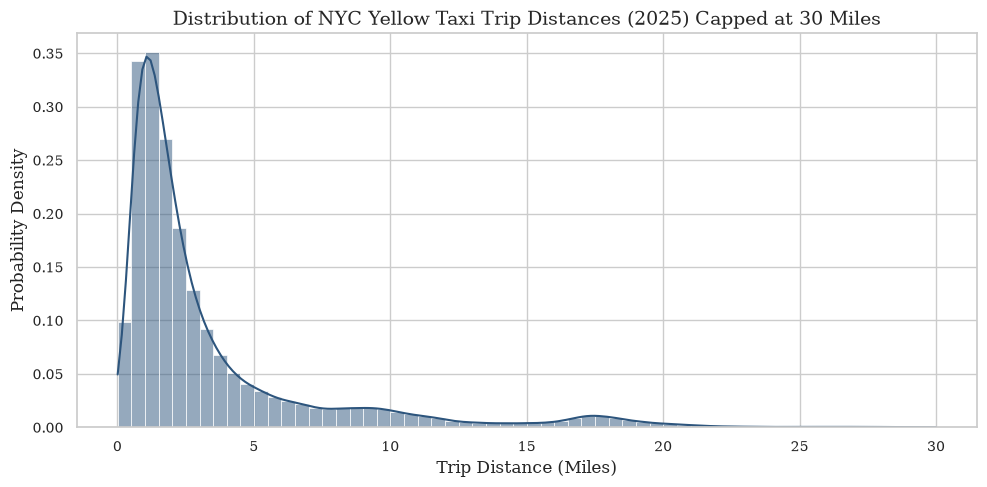

Plot successfully generated and saved to '../reports/figures/trip_distance_distribution.png'!


In [40]:
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style for professional reports
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.autolayout': True
})

# Connect to DuckDB in-memory database
con = duckdb.connect(database=':memory:')

print("Extracting a representative sample of clean trip distances from 2025 data...")

# Query clean data, capping at 30 miles for visualization clarity, and taking a random sample of 500k rows
query = """
SELECT trip_distance
FROM '../data/processed/yellow_tripdata_2025_clean.parquet'
WHERE trip_distance <= 30
USING SAMPLE 500000;
"""

df_dist = con.execute(query).df()
con.close()

print(f"Loaded {len(df_dist):,} sampled records for plotting.")

print("Generating trip distance distribution plot...")
plt.figure(figsize=(10, 5))

# Plot histogram with a Kernel Density Estimate (KDE) curve
ax = sns.histplot(
    df_dist['trip_distance'], 
    bins=60, 
    kde=True, 
    color='#2D557D', 
    stat='density',
    edgecolor='white',
    linewidth=0.5
)

plt.title('Distribution of NYC Yellow Taxi Trip Distances (2025) Capped at 30 Miles')
plt.xlabel('Trip Distance (Miles)')
plt.ylabel('Probability Density')

# Save figure for your LaTeX report
plt.savefig('../reports/figures/trip_distance_distribution.png', dpi=300)
plt.show()

print("Plot successfully generated and saved to '../reports/figures/trip_distance_distribution.png'!")

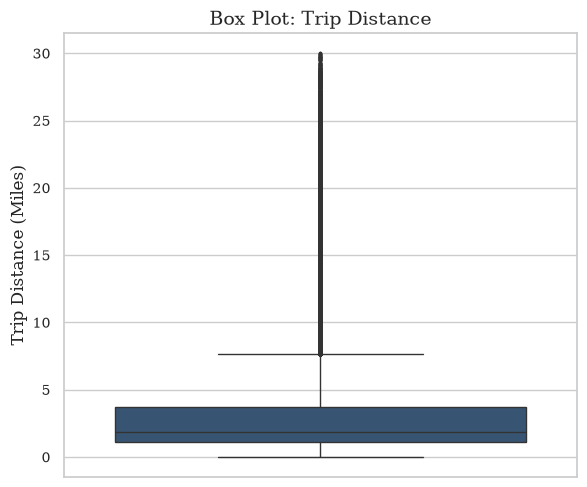

In [41]:
plt.figure(figsize=(6, 5))
sns.boxplot(y=df_dist['trip_distance'], color='#2D557D', fliersize=1.5, linewidth=1)
plt.title('Box Plot: Trip Distance')
plt.ylabel('Trip Distance (Miles)')
plt.savefig('../reports/figures/trip_distance_boxplot.png', dpi=300)
plt.show()

In [61]:
import duckdb as duckdb

query = """
    SELECT 
        COUNT(*) AS count
    FROM '../data/processed/yellow_tripdata_2025_clean.parquet'
    WHERE
        trip_distance > 30; 
"""

con = duckdb.connect(database=':memory:')

con.execute(query).df()

,count
0,41581


In [43]:
import duckdb

query = """
SELECT 
    t.tpep_pickup_datetime,
    t.tpep_dropoff_datetime,
    t.passenger_count,
    t.trip_distance,
    t.fare_amount,
    pu.Borough AS pickup_borough,
    pu.Zone AS pickup_zone,
    d.Borough AS dropoff_borough,
    d.Zone AS dropoff_zone
FROM "../data/processed/yellow_tripdata_2025_clean.parquet" t
LEFT JOIN "../data/spatial/taxi_zone_lookup.csv" pu 
    ON t.PULocationID = pu.LocationID
LEFT JOIN "../data/spatial/taxi_zone_lookup.csv" d 
    ON t.DOLocationID = d.LocationID
WHERE t.trip_distance > 30
ORDER BY t.trip_distance DESC;
"""

con = duckdb.connect(database=':memory:')
df = con.execute(query).df().head(10)
con.close()

print("Sample of trips with trip_distance > 30 miles (excluding location IDs):")
print(df.to_string(index=False))

Sample of trips with trip_distance > 30 miles (excluding location IDs):
tpep_pickup_datetime tpep_dropoff_datetime  passenger_count  trip_distance  fare_amount pickup_borough                  pickup_zone dropoff_borough   dropoff_zone
 2025-05-31 10:28:00   2025-05-31 12:33:35                1          99.82       105.90         Queens             South Ozone Park             N/A Outside of NYC
 2025-11-21 12:00:04   2025-11-21 14:21:19                2          99.81       200.00      Manhattan                 Clinton East             N/A Outside of NYC
 2025-06-05 16:40:45   2025-06-05 19:15:58                1          99.80       358.60         Queens                  JFK Airport             N/A Outside of NYC
 2025-10-12 21:57:42   2025-10-13 01:28:47                1          99.80       122.00         Queens    Springfield Gardens South        Brooklyn      Bay Ridge
 2025-07-04 21:04:38   2025-07-04 22:49:35                1          99.73       637.90      Manhattan Penn Stati

In [73]:
import duckdb

con = duckdb.connect(database=':memory:')

print("Computing descriptive statistics for fare_amount on the clean dataset...")

stats_query = """
SELECT 
    COUNT(fare_amount) AS total_valid_trips,
    AVG(fare_amount) AS mean_val,
    QUANTILE_CONT(fare_amount, 0.25) AS q1,
    QUANTILE_CONT(fare_amount, 0.5) AS median_val,
    QUANTILE_CONT(fare_amount, 0.75) AS q3,
    STDDEV(fare_amount) AS std_val,
    QUANTILE_CONT(fare_amount, 0.75) - QUANTILE_CONT(fare_amount, 0.25) AS iqr_val,
    SKEWNESS(fare_amount) AS skewness_val
FROM '../data/processed/yellow_tripdata_2025_clean.parquet';
"""

df_stats = con.execute(stats_query).df()
con.close()

print("\n--- Statistical Summary for fare_amount ---")
print(df_stats.to_string(index=False))

Computing descriptive statistics for fare_amount on the clean dataset...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


--- Statistical Summary for fare_amount ---
 total_valid_trips  mean_val  q1  median_val   q3    std_val  iqr_val  skewness_val
          44041005  20.04464 9.3        14.2 23.3 149.702038     14.0   4834.150065


Extracting sampled clean fare amounts for plotting...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Loaded 498,472 sampled records. Generating plot...


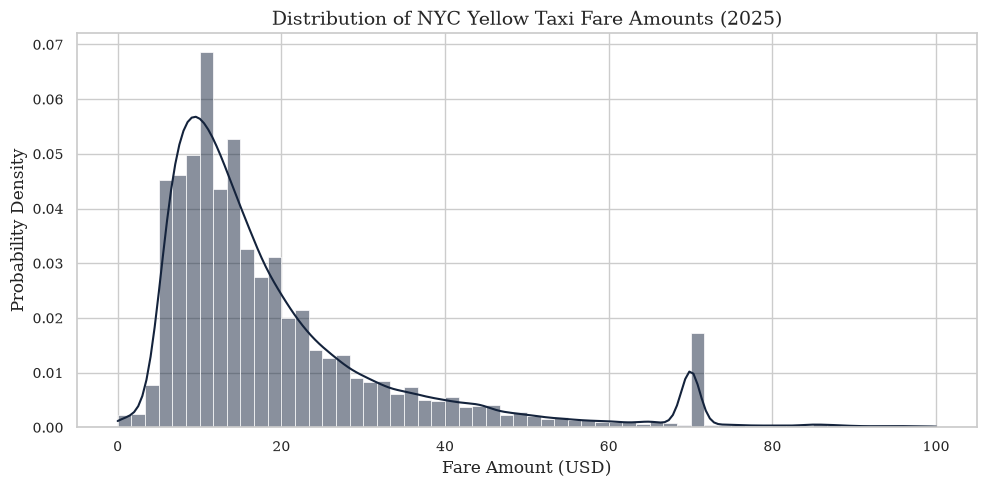

Plot saved to '../reports/figures/fare_amount_distribution.png'!


In [45]:
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.autolayout': True
})

con = duckdb.connect(database=':memory:')

print("Extracting sampled clean fare amounts for plotting...")
query = """
SELECT fare_amount
FROM '../data/processed/yellow_tripdata_2025_clean.parquet'
WHERE 
    EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 60.0 > 0
    AND trip_distance > 0
    AND fare_amount >= 0
    AND fare_amount <= 100
USING SAMPLE 500000;
"""

df_fare = con.execute(query).df()
con.close()

print(f"Loaded {len(df_fare):,} sampled records. Generating plot...")

plt.figure(figsize=(10, 5))
ax = sns.histplot(
    df_fare['fare_amount'], 
    bins=60, 
    kde=True, 
    color='#14233C', 
    stat='density',
    edgecolor='white',
    linewidth=0.5
)

plt.title('Distribution of NYC Yellow Taxi Fare Amounts (2025)')
plt.xlabel('Fare Amount (USD)')
plt.ylabel('Probability Density')

plt.savefig('../reports/figures/fare_amount_distribution.png', dpi=300)
plt.show()

print("Plot saved to '../reports/figures/fare_amount_distribution.png'!")

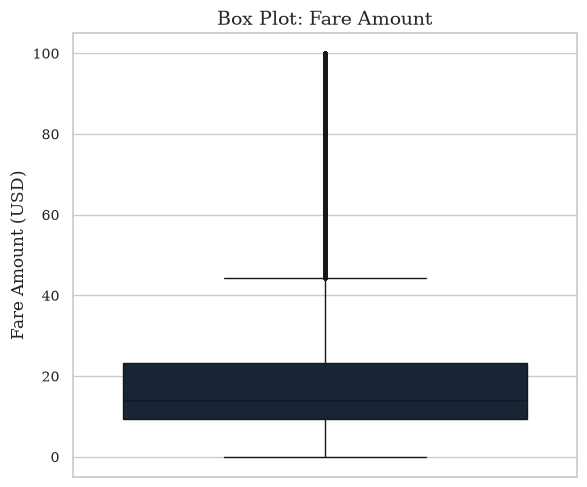

In [46]:
plt.figure(figsize=(6, 5))
sns.boxplot(y=df_fare['fare_amount'], color='#14233C', fliersize=1.5, linewidth=1)
plt.title('Box Plot: Fare Amount')
plt.ylabel('Fare Amount (USD)')
plt.savefig('../reports/figures/fare_amount_boxplot.png', dpi=300)
plt.show()

In [72]:
import duckdb

con = duckdb.connect(database=':memory:')

print("Computing descriptive statistics for cbd_congestion_fee on the clean dataset...")

stats_query = """
SELECT 
    COUNT(cbd_congestion_fee) AS total_valid_trips,
    AVG(cbd_congestion_fee) AS mean_val,
    QUANTILE_CONT(cbd_congestion_fee, 0.25) AS q1, 
    QUANTILE_CONT(cbd_congestion_fee, 0.5) AS median_val,
    QUANTILE_CONT(cbd_congestion_fee, 0.75) AS q3,
    STDDEV(cbd_congestion_fee) AS std_val,
    QUANTILE_CONT(cbd_congestion_fee, 0.75) - QUANTILE_CONT(cbd_congestion_fee, 0.25) AS iqr_val,
    SKEWNESS(cbd_congestion_fee) AS skewness_val
FROM '../data/processed/yellow_tripdata_2025_clean.parquet';
"""

df_stats = con.execute(stats_query).df()
con.close()

print("\n--- Statistical Summary for cbd_congestion_fee ---")
print(df_stats.to_string(index=False))

Computing descriptive statistics for cbd_congestion_fee on the clean dataset...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


--- Statistical Summary for cbd_congestion_fee ---
 total_valid_trips  mean_val  q1  median_val   q3  std_val  iqr_val  skewness_val
          44041005  0.547732 0.0        0.75 0.75 0.332944     0.75     -1.039659


Aggregating cbd_congestion_fee frequencies across 2025 data...
Generating CBD congestion fee distribution plot...


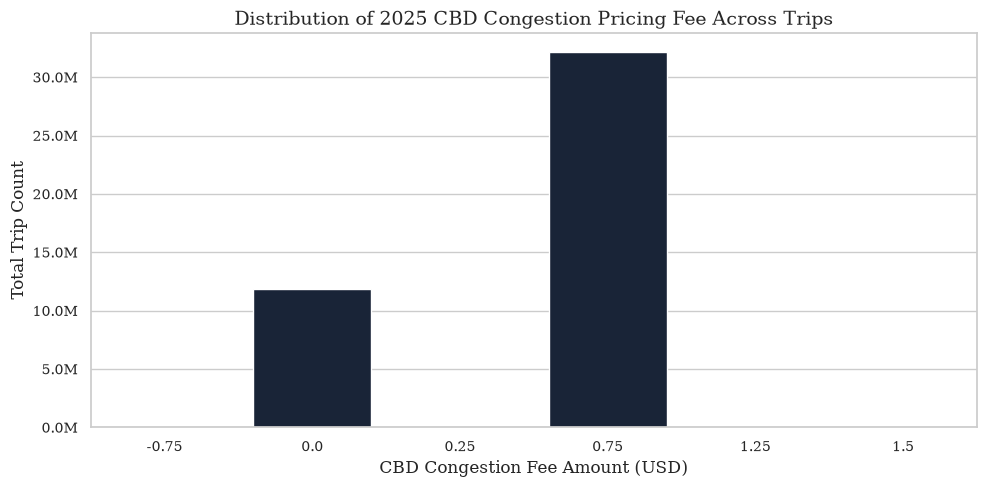

Plot saved to '../reports/figures/cbd_congestion_fee_distribution.png'!


In [48]:
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.autolayout': True
})

con = duckdb.connect(database=':memory:')

print("Aggregating cbd_congestion_fee frequencies across 2025 data...")
query = """
SELECT 
    COALESCE(cbd_congestion_fee, 0.0) AS fee_amount,
    COUNT(*) AS trip_count
FROM '../data/processed/yellow_tripdata_2025_clean.parquet'
WHERE 
    EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 60.0 > 0
    AND trip_distance > 0
    AND fare_amount >= 0
GROUP BY fee_amount
ORDER BY fee_amount;
"""

df_cbd = con.execute(query).df()
con.close()

print("Generating CBD congestion fee distribution plot...")
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x='fee_amount',
    y='trip_count',
    data=df_cbd,
    color='#14233C'
)

plt.title('Distribution of 2025 CBD Congestion Pricing Fee Across Trips')
plt.xlabel('CBD Congestion Fee Amount (USD)')
plt.ylabel('Total Trip Count')

# Format y-axis in millions
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"{x*1e-6:.1f}M"))

plt.savefig('../reports/figures/cbd_congestion_fee_distribution.png', dpi=300)
plt.show()

print("Plot saved to '../reports/figures/cbd_congestion_fee_distribution.png'!")

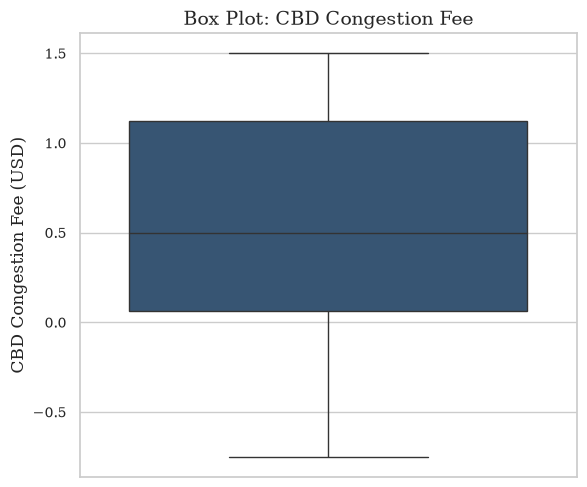

In [49]:
plt.figure(figsize=(6, 5))
sns.boxplot(y=df_cbd['fee_amount'], color='#2D557D', fliersize=1.5, linewidth=1)
plt.title('Box Plot: CBD Congestion Fee')
plt.ylabel('CBD Congestion Fee (USD)')
plt.savefig('../reports/figures/cbd_congestion_fee_boxplot.png', dpi=300)
plt.show()

In [71]:
import duckdb

con = duckdb.connect(database=':memory:')

print("Computing descriptive statistics for passenger_count on the clean dataset...")

stats_query = """
SELECT 
    COUNT(passenger_count) AS total_valid_trips,
    MODE(passenger_count) AS mode_val,
    AVG(passenger_count::DOUBLE) AS mean_val,
    QUANTILE_CONT(passenger_count, 0.25) AS q1,
    QUANTILE_CONT(passenger_count, 0.5) AS median_val,
    QUANTILE_CONT(passenger_count, 0.75) AS q3,
    STDDEV(passenger_count::DOUBLE) AS std_val,
    QUANTILE_CONT(passenger_count, 0.75) - QUANTILE_CONT(passenger_count, 0.25) AS iqr_val,
    SKEWNESS(passenger_count::DOUBLE) AS skewness_val
FROM '../data/processed/yellow_tripdata_2025_clean.parquet';
"""

df_stats = con.execute(stats_query).df()
con.close()

print("\n--- Statistical Summary for passenger_count ---")
print(df_stats.to_string(index=False))

Computing descriptive statistics for passenger_count on the clean dataset...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


--- Statistical Summary for passenger_count ---
 total_valid_trips  mode_val  mean_val  q1  median_val  q3  std_val  iqr_val  skewness_val
          35196988         1  1.292306 1.0         1.0 1.0 0.726253      0.0      2.968505


Aggregating passenger count frequencies across 2025 data...
Generating passenger count distribution plot...


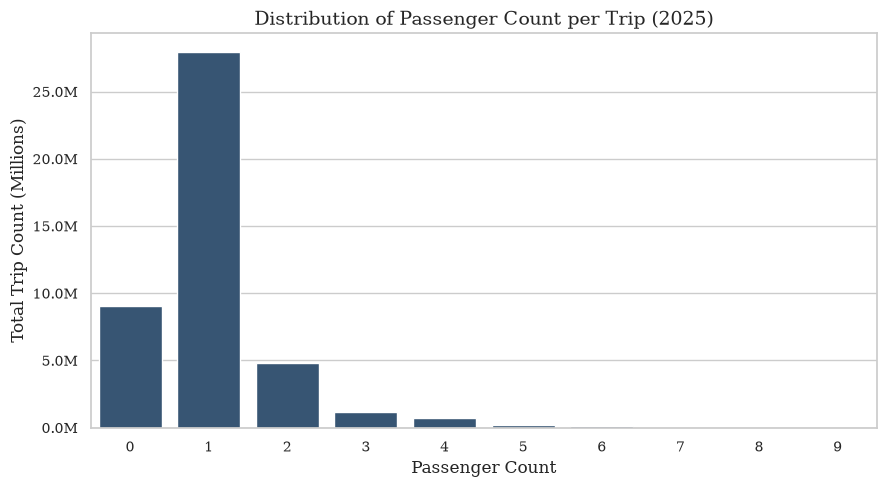

Plot saved to '../reports/figures/passenger_count_distribution.png'!


In [51]:
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.autolayout': True
})

con = duckdb.connect(database=':memory:')

print("Aggregating passenger count frequencies across 2025 data...")
query = """
SELECT 
    COALESCE(passenger_count, 0) AS p_count,
    COUNT(*) AS trip_count
FROM '../data/processed/yellow_tripdata_2025_clean.parquet'
WHERE 
    EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 60.0 > 0
    AND trip_distance > 0
    AND fare_amount >= 0
GROUP BY p_count
ORDER BY p_count;
"""

df_pass = con.execute(query).df()
con.close()

print("Generating passenger count distribution plot...")
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x='p_count',
    y='trip_count',
    data=df_pass,
    color='#2D557D'
)

plt.title('Distribution of Passenger Count per Trip (2025)')
plt.xlabel('Passenger Count')
plt.ylabel('Total Trip Count (Millions)')

# Format y-axis in millions
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"{x*1e-6:.1f}M"))

plt.savefig('../reports/figures/passenger_count_distribution.png', dpi=300)
plt.show()

print("Plot saved to '../reports/figures/passenger_count_distribution.png'!")

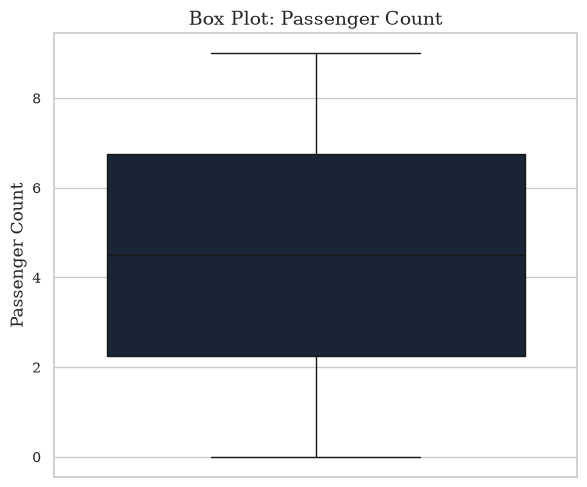

In [52]:
plt.figure(figsize=(6, 5))
sns.boxplot(y=df_pass['p_count'], color='#14233C', fliersize=1.5, linewidth=1)
plt.title('Box Plot: Passenger Count')
plt.ylabel('Passenger Count')
plt.savefig('../reports/figures/passenger_count_boxplot.png', dpi=300)
plt.show()

In [70]:
import duckdb

con = duckdb.connect(database=':memory:')

print("Computing descriptive statistics for tip_amount on the clean dataset...")

stats_query = """
SELECT 
    COUNT(tip_amount) AS total_valid_trips,
    AVG(tip_amount) AS mean_val,
    QUANTILE_CONT(tip_amount, 0.25) AS q1,
    QUANTILE_CONT(tip_amount, 0.5) AS median_val,
    QUANTILE_CONT(tip_amount, 0.75) AS q3,
    STDDEV(tip_amount) AS std_val,
    QUANTILE_CONT(tip_amount, 0.75) - QUANTILE_CONT(tip_amount, 0.25) AS iqr_val,
    SKEWNESS(tip_amount) AS skewness_val
FROM '../data/processed/yellow_tripdata_2025_clean.parquet';
"""

df_stats = con.execute(stats_query).df()
con.close()

print("\n--- Statistical Summary for tip_amount ---")
print(df_stats.to_string(index=False))

Computing descriptive statistics for tip_amount on the clean dataset...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


--- Statistical Summary for tip_amount ---
 total_valid_trips  mean_val  q1  median_val   q3  std_val  iqr_val  skewness_val
          44041005  3.040513 0.0        2.39 4.07 3.957863     4.07      4.509302


Extracting sampled clean tip amounts for plotting...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Loaded 499,594 sampled records. Generating plot...


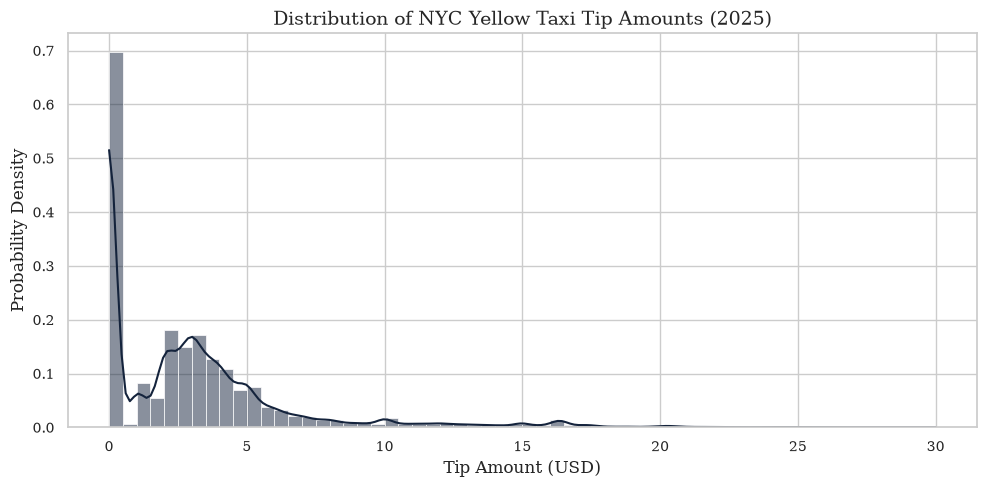

Plot saved to '../reports/figures/tip_amount_distribution.png'!


In [54]:
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.autolayout': True
})

con = duckdb.connect(database=':memory:')

print("Extracting sampled clean tip amounts for plotting...")
query = """
SELECT tip_amount
FROM '../data/processed/yellow_tripdata_2025_clean.parquet'
WHERE 
    EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 60.0 > 0
    AND trip_distance > 0
    AND fare_amount >= 0
    AND tip_amount >= 0
    AND tip_amount <= 30
USING SAMPLE 500000;
"""

df_tip = con.execute(query).df()
con.close()

print(f"Loaded {len(df_tip):,} sampled records. Generating plot...")

plt.figure(figsize=(10, 5))
ax = sns.histplot(
    df_tip['tip_amount'], 
    bins=60, 
    kde=True, 
    color='#14233C', 
    stat='density',
    edgecolor='white',
    linewidth=0.5
)

plt.title('Distribution of NYC Yellow Taxi Tip Amounts (2025)')
plt.xlabel('Tip Amount (USD)')
plt.ylabel('Probability Density')

plt.savefig('../reports/figures/tip_amount_distribution.png', dpi=300)
plt.show()

print("Plot saved to '../reports/figures/tip_amount_distribution.png'!")

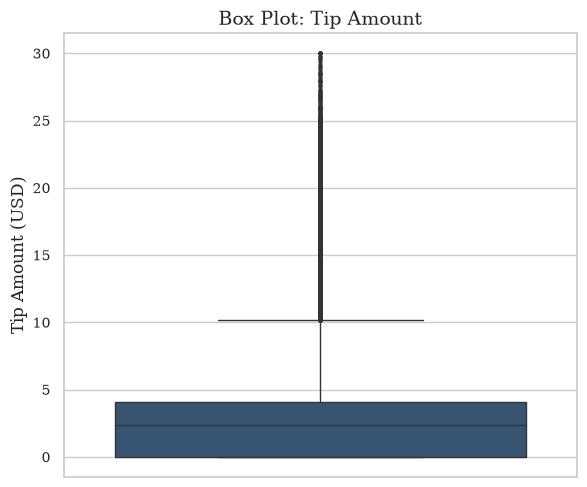

In [55]:
plt.figure(figsize=(6, 5))
sns.boxplot(y=df_tip['tip_amount'], color='#2D557D', fliersize=1.5, linewidth=1)
plt.title('Box Plot: Tip Amount')
plt.ylabel('Tip Amount (USD)')
plt.savefig('../reports/figures/tip_amount_boxplot.png', dpi=300)
plt.show()

In [74]:
import duckdb

con = duckdb.connect(database=':memory:')

print("Computing descriptive statistics for trip_duration_minutes on the clean dataset...")

stats_query = """
WITH clean_filtered AS (
    SELECT 
        EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 60.0 AS trip_duration_minutes
    FROM '../data/processed/yellow_tripdata_2025_clean.parquet'
    WHERE 
        EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 60.0 > 0
        AND trip_distance > 0
        AND fare_amount >= 0
)
SELECT 
    COUNT(trip_duration_minutes) AS total_valid_trips,
    AVG(trip_duration_minutes) AS mean_val,
    QUANTILE_CONT(trip_duration_minutes, 0.25) AS q1,
    QUANTILE_CONT(trip_duration_minutes, 0.5) AS median_val,
    QUANTILE_CONT(trip_duration_minutes, 0.75) AS q3,
    STDDEV(trip_duration_minutes) AS std_val,
    QUANTILE_CONT(trip_duration_minutes, 0.75) - QUANTILE_CONT(trip_duration_minutes, 0.25) AS iqr_val,
    SKEWNESS(trip_duration_minutes) AS skewness_val
FROM clean_filtered;
"""

df_stats = con.execute(stats_query).df()
con.close()

print("\n--- Statistical Summary for trip_duration_minutes ---")
print(df_stats.to_string(index=False))

Computing descriptive statistics for trip_duration_minutes on the clean dataset...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


--- Statistical Summary for trip_duration_minutes ---
 total_valid_trips  mean_val  q1  median_val        q3   std_val   iqr_val  skewness_val
          44041005 17.621743 8.3   13.533333 21.533333 27.408662 13.233333     54.528757


Extracting a representative sample of clean trip durations from processed data...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Loaded 489,906 sampled records for plotting.
Generating trip duration distribution plot...


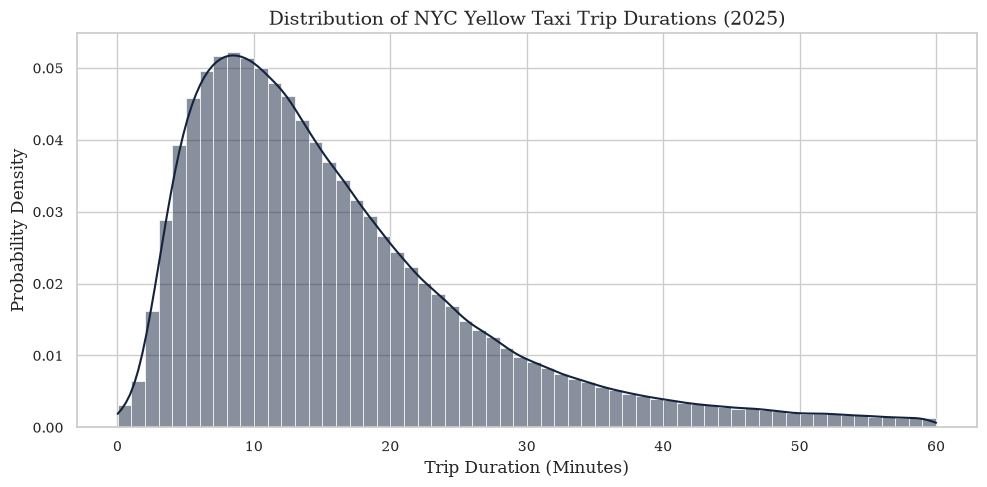

Plot successfully generated and saved to '../reports/figures/trip_duration_distribution.png'!


In [57]:
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style for professional reports
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.autolayout': True
})

# Connect to DuckDB in-memory database
con = duckdb.connect(database=':memory:')

print("Extracting a representative sample of clean trip durations from processed data...")

# Query processed data, calculating duration in minutes, capping at 60 mins for visualization
query = """
SELECT 
    EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 60.0 AS trip_duration_minutes
FROM '../data/processed/yellow_tripdata_2025_clean.parquet'
WHERE 
    EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 60.0 > 0
    AND EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 60.0 <= 60
USING SAMPLE 500000;
"""

df_duration = con.execute(query).df()
con.close()

print(f"Loaded {len(df_duration):,} sampled records for plotting.")

print("Generating trip duration distribution plot...")
plt.figure(figsize=(10, 5))

# Plot histogram with a Kernel Density Estimate (KDE) curve
ax = sns.histplot(
    df_duration['trip_duration_minutes'], 
    bins=60, 
    kde=True, 
    color='#14233C', 
    stat='density',
    edgecolor='white',
    linewidth=0.5
)

plt.title('Distribution of NYC Yellow Taxi Trip Durations (2025)')
plt.xlabel('Trip Duration (Minutes)')
plt.ylabel('Probability Density')

# Save figure for your LaTeX report
plt.savefig('../reports/figures/trip_duration_distribution.png', dpi=300)
plt.show()

print("Plot successfully generated and saved to '../reports/figures/trip_duration_distribution.png'!")

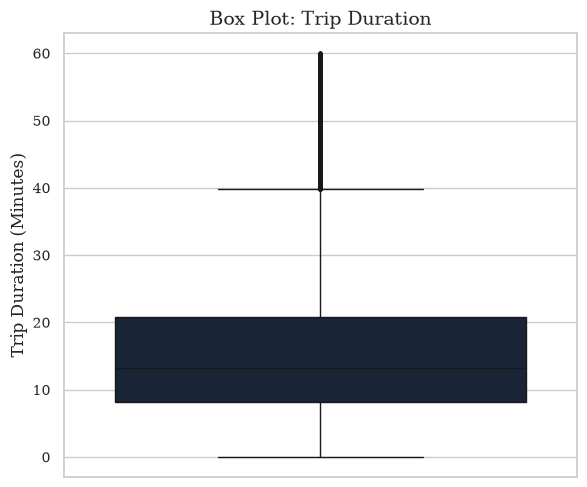

In [58]:
plt.figure(figsize=(6, 5))
sns.boxplot(y=df_duration['trip_duration_minutes'], color='#14233C', fliersize=1.5, linewidth=1)
plt.title('Box Plot: Trip Duration')
plt.ylabel('Trip Duration (Minutes)')
plt.savefig('../reports/figures/trip_duration_boxplot.png', dpi=300)
plt.show()